In [1]:
import sqlite3
import os
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report ,precision_score, recall_score,roc_auc_score, confusion_matrix, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_predict

In [2]:
conn = sqlite3.connect("olist.db")

files = {
    "raw_customers":"olist_customers_dataset.csv",
    "raw_orders":"olist_orders_dataset.csv",
    "raw_order_items":"olist_order_items_dataset.csv",
    "raw_order_payments":"olist_order_payments_dataset.csv"
}

for table , file in files.items():
    df  = pd.read_csv(file,dtype={"cunstomer_zip_code_prefix":str})
    df.to_sql(table,conn,if_exists="replace",index=False)
    print(table,df.shape)

tables  = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'",conn)
print(tables)

conn.close()

raw_customers (99441, 5)
raw_orders (99441, 8)
raw_order_items (112650, 7)
raw_order_payments (103886, 5)
                 name
0         raw_sellers
1        clean_orders
2       raw_customers
3          raw_orders
4     raw_order_items
5  raw_order_payments


In [3]:
conn = sqlite3.connect("olist.db")

for table in ["raw_customers","raw_orders","raw_order_items","raw_order_payments"]:
    n = pd.read_sql(f"SELECT COUNT(*) AS rows_count FROM {table}",conn)
    print(table,n["rows_count"][0])

# status = pd.read_sql("""
#     SELECT order_status,
#         COUNT(*) AS n,
#         SUM(order_delivered_customer_date IS NULL) AS missing_delivery_date
#     FROM raw_orders
#     GROUP BY order_status
#     ORDER BY n DESC   
# """,conn)
status = pd.read_sql("""
    SELECT order_status,
           COUNT(*) AS n,
           SUM(order_delivered_customer_date IS NULL) AS missing_delivery_date
    FROM raw_orders
    GROUP BY order_status
    ORDER BY n DESC
""", conn)



display(status)
conn.close()


raw_customers 99441
raw_orders 99441
raw_order_items 112650
raw_order_payments 103886


,order_status,n,missing_delivery_date
0,delivered,96478,8
1,shipped,1107,1107
2,canceled,625,619
3,unavailable,609,609
4,invoiced,314,314
5,processing,301,301
6,created,5,5
7,approved,2,2


In [4]:
conn = sqlite3.connect("olist.db")

orders = pd.read_sql("""
    SELECT order_id , order_delivered_customer_date , order_estimated_delivery_date
    FROM raw_orders
    WHERE order_status = 'delivered'
    AND order_delivered_customer_date IS NOT NULL
""",conn)

conn.close()

orders["delivered_day"] = pd.to_datetime(orders["order_delivered_customer_date"]).dt.normalize()
orders["estimated_day"] = pd.to_datetime(orders["order_estimated_delivery_date"]).dt.normalize()
orders["is_late"] = (orders["delivered_day"] > orders["estimated_day"]).astype(int)

print(len(orders))
print(orders["is_late"].sum())
print(round(orders["is_late"].mean()*100,2))

96470
6534
6.77


In [5]:
conn  = sqlite3.connect("olist.db")

items_agg  = pd.read_sql("""
    SELECT order_id,
        COUNT(*) AS n_items,
        SUM(price) AS total_price,
        SUM(freight_value)  AS total_freight
    FROM raw_order_items
    GROUP BY order_id    
""",conn)
conn.close()
print(items_agg.shape)
print(items_agg["order_id"].nunique())
display(items_agg.head())

(98666, 4)
98666


,order_id,n_items,total_price,total_freight
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14


In [6]:
conn =  sqlite3.connect("olist.db")

pay_agg = pd.read_sql("""
    SELECT order_id,
        COUNT(*) AS n_payments,
        SUM(payment_value) AS total_value,
        MAX(payment_installments) AS max_intstallments
    FROM raw_order_payments
    GROUP BY order_id    
""",conn)

conn.close()

print(pay_agg.shape)
print(pay_agg["order_id"].nunique())
display(pay_agg.head())

(99440, 4)
99440


,order_id,n_payments,total_value,max_intstallments
0,00010242fe8c5a6d1ba2dd792cb16214,1,72.19,2
1,00018f77f2f0320c557190d7a144bdd3,1,259.83,3
2,000229ec398224ef6ca0657da4fc703e,1,216.87,5
3,00024acbcdf0a6daa1e931b038114c75,1,25.78,2
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,218.04,3


In [7]:
conn  = sqlite3.connect("olist.db")
sellers = pd.read_csv("olist_sellers_dataset.csv")
print(sellers.shape)

sellers.to_sql("raw_sellers",conn,if_exists="replace",index=False)

check = pd.read_sql("SELECT * FROM raw_sellers LIMIT 5",conn)
display(check)

(3095, 4)


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [8]:
conn = sqlite3.connect("olist.db")

work =  pd.read_sql("""
    WITH items AS (
        SELECT order_id,
            COUNT(*) AS n_items,
            SUM(price) AS total_price,
            SUM(freight_value) AS total_freight
        FROM raw_order_items
        GROUP BY order_id    
    ),
    pay AS(
        SELECT order_id,
            COUNT(*) AS n_payments,
            SUM(payment_value) AS total_payment,
            MAX(payment_installments) AS max_installments
        FROM raw_order_payments
        GROUP BY order_id
    )
    SELECT o.order_id,
           o.order_purchase_timestamp,
           o.order_estimated_delivery_date,
           o.order_delivered_customer_date,
           c.customer_state,
           i.n_items,i.total_price,i.total_freight,
           p.n_payments,p.total_payment,p.max_installments
    FROM raw_orders AS o
    LEFT JOIN raw_customers AS c ON o.customer_id = c.customer_id
    LEFT JOIN items  AS i ON o.order_id = i.order_id
    LEFT JOIN pay AS p on o.order_id = p.order_id
    WHERE o.order_status  = 'delivered'
        AND o.order_delivered_customer_date IS NOT NULL

""",conn)
conn.close()

print(work.shape)
print(work["order_id"].nunique())
print("hi\n",work.isna().sum())

(96470, 11)
96470
hi
 order_id                         0
order_purchase_timestamp         0
order_estimated_delivery_date    0
order_delivered_customer_date    0
customer_state                   0
n_items                          0
total_price                      0
total_freight                    0
n_payments                       1
total_payment                    1
max_installments                 1
dtype: int64


In [9]:
df = work.dropna(subset=["n_payments"]).copy()

df["purchase_ts"] = pd.to_datetime(df["order_purchase_timestamp"])
df["delivered_day"] = pd.to_datetime(df["order_delivered_customer_date"]).dt.normalize()
df["estimated_day"] = pd.to_datetime(df["order_estimated_delivery_date"]).dt.normalize()

df["is_late"] = (df["delivered_day"] > df["estimated_day"]).astype(int)
df["est_days"] = (df["estimated_day"] - df["purchase_ts"].dt.normalize()).dt.days
df["purchase_month"] = df["purchase_ts"].dt.month
df["purchase_weekday"] = df["purchase_ts"].dt.dayofweek
df["purchase_hour"] = df["purchase_ts"].dt.hour

print(df.shape)
print(round(df["is_late"].mean() * 100 ,2))
display(df[["est_days","purchase_month","purchase_weekday","purchase_hour","is_late"]].describe())

(96469, 19)
6.77


,est_days,purchase_month,purchase_weekday,purchase_hour,is_late
count,96469.000000,96469.000000,96469.000000,96469.000000,96469.000000
mean,24.372793,6.031015,2.756492,14.773057,0.067721
std,8.758456,3.228482,1.967051,5.328367,0.251268
min,3.000000,1.000000,0.000000,0.000000,0.000000
25%,19.000000,3.000000,1.000000,11.000000,0.000000
50%,24.000000,6.000000,3.000000,15.000000,0.000000
75%,29.000000,8.000000,4.000000,19.000000,0.000000
max,156.000000,12.000000,6.000000,23.000000,1.000000


In [10]:
clean_cols = ["order_id","is_late","est_days","purchase_month","purchase_weekday","purchase_hour","customer_state","n_items","total_price","total_freight","n_payments","total_payment","max_installments"]

conn = sqlite3.connect("olist.db")
df[clean_cols].to_sql("clean_orders", conn, if_exists="replace", index=False)
check=pd.read_sql("SELECT COUNT(*) AS n ,SUM(is_late) AS late FROM clean_orders",conn)
display(check)

tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table' ",conn)
display(tables)

conn.close()

,n,late
0,96469,6533


,name
0,raw_customers
1,raw_orders
2,raw_order_items
3,raw_order_payments
4,raw_sellers
5,clean_orders


In [11]:
conn = sqlite3.connect("olist.db")

data = pd.read_sql("SELECT * FROM clean_orders",conn)
conn.close()

print(data.shape)
print(data.dtypes)

X = data.drop(columns=["is_late","order_id"])
y= data["is_late"]

X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size= 0.2,random_state=42,stratify=y
)

print(X_train.shape,X_test.shape)
print(round(y_train.mean() * 100 , 2) , round(y_test.mean() * 100 ,2))

(96469, 13)
order_id                str
is_late               int64
est_days              int64
purchase_month        int64
purchase_weekday      int64
purchase_hour         int64
customer_state          str
n_items               int64
total_price         float64
total_freight       float64
n_payments          float64
total_payment       float64
max_installments    float64
dtype: object
(77175, 11) (19294, 11)
6.77 6.77


In [12]:
X_train_enc = pd.get_dummies(X_train,columns=["customer_state"],drop_first=True,dtype=int)
X_test_enc = pd.get_dummies(X_test,columns=["customer_state"],drop_first=True,dtype=int)
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns,fill_value=0)

print(X_train_enc.shape,X_test_enc.shape)
print(X_train_enc.isna().sum().sum())
print(list(X_train_enc.columns))

(77175, 36) (19294, 36)
0
['est_days', 'purchase_month', 'purchase_weekday', 'purchase_hour', 'n_items', 'total_price', 'total_freight', 'n_payments', 'total_payment', 'max_installments', 'customer_state_AL', 'customer_state_AM', 'customer_state_AP', 'customer_state_BA', 'customer_state_CE', 'customer_state_DF', 'customer_state_ES', 'customer_state_GO', 'customer_state_MA', 'customer_state_MG', 'customer_state_MS', 'customer_state_MT', 'customer_state_PA', 'customer_state_PB', 'customer_state_PE', 'customer_state_PI', 'customer_state_PR', 'customer_state_RJ', 'customer_state_RN', 'customer_state_RO', 'customer_state_RR', 'customer_state_RS', 'customer_state_SC', 'customer_state_SE', 'customer_state_SP', 'customer_state_TO']


In [13]:
train_eda = X_train.copy()
train_eda["is_late"] = y_train
display(train_eda.head())

,est_days,purchase_month,purchase_weekday,purchase_hour,customer_state,n_items,total_price,total_freight,n_payments,total_payment,max_installments,is_late
45508,42,6,3,0,MS,1,1139.00,41.51,1.0,1180.51,10.0,0
78440,9,8,1,10,SP,1,15.90,7.39,1.0,23.29,1.0,0
92592,26,4,2,18,RJ,1,59.99,15.30,1.0,75.29,1.0,0
86653,20,2,1,15,SP,1,86.90,16.24,4.0,103.14,3.0,0
706,7,8,3,12,SP,1,123.47,9.02,1.0,132.49,6.0,0


In [14]:
by_state = train_eda.groupby("customer_state")["is_late"].agg(["count","mean"])
display(by_state.sort_values("mean",ascending=False).round(3))

,count,mean
customer_state,,
AL,319,0.232
MA,584,0.176
SE,270,0.148
PI,405,0.138
CE,1004,0.131
BA,2580,0.122
RJ,9901,0.121
PB,406,0.111
PA,741,0.109


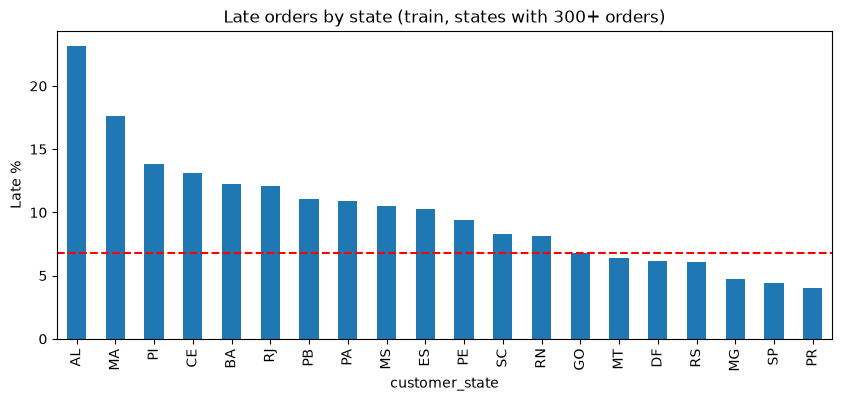

In [15]:
big = by_state[by_state["count"] > 300].sort_values("mean",ascending=False)
(big["mean"]*100).plot(kind="bar", figsize=(10,4))
plt.axhline(6.77,color="red",linestyle="--")
plt.ylabel("Late %")
plt.title("Late orders by state (train, states with 300+ orders)")
plt.savefig("late_by_state.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
train_eda.groupby("is_late")["est_days"].agg(["count","mean","median"])

,count,mean,median
is_late,,,
0,71949,24.450819,24.0
1,5226,23.293341,23.0


In [17]:
train_eda["est_bin"] = pd.cut(train_eda["est_days"],bins=[0, 15, 20, 25, 30, 40, 200])
display(train_eda.groupby("est_bin",observed=True)["is_late"].agg(["count","mean"]).round(3))

,count,mean
est_bin,,
"(0, 15]",11263,0.059
"(15, 20]",13287,0.072
"(20, 25]",21165,0.081
"(25, 30]",15557,0.070
"(30, 40]",12799,0.056
"(40, 200]",3104,0.023


In [18]:
display(train_eda.groupby("purchase_month")["is_late"].agg(["count","mean"]).round(3))

,count,mean
purchase_month,,
1,6254,0.053
2,6587,0.119
3,7625,0.152
4,7273,0.050
5,8254,0.054
6,7434,0.017
7,8086,0.032
8,8427,0.049
9,3271,0.042


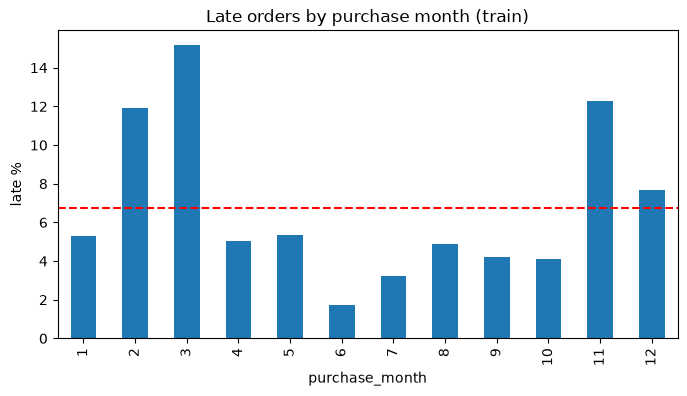

In [19]:
month_late = train_eda.groupby("purchase_month")["is_late"].mean()*100
month_late.plot(kind="bar",figsize=(8,4))
plt.axhline(6.77,color="red",linestyle="--")
plt.ylabel("late %")
plt.title("Late orders by purchase month (train)")
plt.savefig("late_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

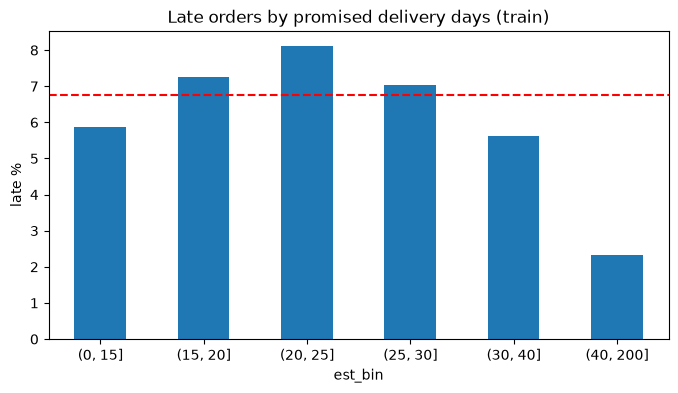

In [20]:
est_late = train_eda.groupby("est_bin",observed=True)["is_late"].mean()* 100
est_late.plot(kind="bar",figsize=(8,4),rot=0)
plt.axhline(6.77, color="red", linestyle="--")
plt.ylabel("late %")
plt.title("Late orders by promised delivery days (train)")
plt.savefig("late_by_est_days.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
y_pred_base = np.zeros(len(y_train),dtype=int)
print(classification_report(y_train,y_pred_base,zero_division=0))

              precision    recall  f1-score   support

           0       0.93      1.00      0.96     71949
           1       0.00      0.00      0.00      5226

    accuracy                           0.93     77175
   macro avg       0.47      0.50      0.48     77175
weighted avg       0.87      0.93      0.90     77175



In [22]:
for cw in [None,"balanced"]:
    pipe = Pipeline([
        ("scaler",  StandardScaler()),
        ("model", LogisticRegression(max_iter=1000,class_weight=cw))
    ])

    for metric in ["precision","recall","f1"]:
     scores = cross_val_score(pipe,X_train_enc,y_train,cv=5,scoring=metric)
     print(cw,metric,round(scores.mean(),2))

c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


None precision 0.2
None recall 0.0
None f1 0.0
balanced precision 0.12
balanced recall 0.62
balanced f1 0.19


In [23]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(spw)

models = {
    "LogReg balanced": Pipeline([
        ("scaler" , StandardScaler()),
        ("model", LogisticRegression(max_iter=1000,class_weight="balanced"))
    ]),
    "XGBoost": XGBClassifier(n_estimators=100,learning_rate=0.1,max_depth=3,scale_pos_weight=spw,random_state=42)
}

for name,model in models.items():
    for metric in ["roc_auc","precision","recall","f1"]:
        scores = cross_val_score(model, X_train_enc, y_train, cv=5, scoring=metric)
        print(name, metric, round(scores.mean(), 3)) 

13.767508610792193
LogReg balanced roc_auc 0.685
LogReg balanced precision 0.116
LogReg balanced recall 0.616
LogReg balanced f1 0.195
XGBoost roc_auc 0.766
XGBoost precision 0.156
XGBoost recall 0.672
XGBoost f1 0.253


In [24]:
for depth in[2,3,4,6]:
    xgb_d = XGBClassifier(n_estimators=100,learning_rate=0.1,max_depth=depth, scale_pos_weight=spw,random_state=42)
    scores = cross_val_score(xgb_d, X_train_enc, y_train, cv=5, scoring="roc_auc")
    print("Depth",depth,"::","Mean::",round(scores.mean(), 3),"STD::", round(scores.std(), 3))

Depth 2 :: Mean:: 0.758 STD:: 0.007
Depth 3 :: Mean:: 0.766 STD:: 0.006
Depth 4 :: Mean:: 0.769 STD:: 0.007
Depth 6 :: Mean:: 0.763 STD:: 0.007


In [25]:
xgb_final = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,scale_pos_weight=spw, random_state=42)

proba = cross_val_predict(xgb_final, X_train_enc, y_train, cv=5, method="predict_proba")[:, 1]
print(proba.shape)

for t in [0.3,0.4,0.5,0.6,0.7,0.8]:
    pred = (proba >= t).astype(int)

    print(t,
           "Precision::",round(precision_score(y_train,pred),3),
           "Recall::",round(recall_score(y_train,pred),3),
           "flagged %:",round(pred.mean()*100,3)     
    )

(77175,)
0.3 Precision:: 0.089 Recall:: 0.92 flagged %: 70.159
0.4 Precision:: 0.117 Recall:: 0.807 flagged %: 46.532
0.5 Precision:: 0.156 Recall:: 0.672 flagged %: 29.197
0.6 Precision:: 0.197 Recall:: 0.511 flagged %: 17.607
0.7 Precision:: 0.253 Recall:: 0.328 flagged %: 8.787
0.8 Precision:: 0.364 Recall:: 0.143 flagged %: 2.663


In [26]:
THRESH = 0.6

lr_final = Pipeline([
    ("scaler",StandardScaler()),
    ("model",LogisticRegression(max_iter=1000,class_weight="balanced"))
])

lr_final.fit(X_train_enc,y_train)
xgb_final.fit(X_train_enc,y_train)

lr_proba = lr_final.predict_proba(X_test_enc)[:,1]
xgb_proba = xgb_final.predict_proba(X_test_enc)[:,1]

print("Logistic Regression test auc::",round(roc_auc_score(y_test,lr_proba),3))
print("XGBBoost Test auc::",round(roc_auc_score(y_test,xgb_proba),3) )

pred = (xgb_proba >= THRESH).astype(int)

print("XGBoost threshold:", THRESH)
print("precision:", round(precision_score(y_test, pred), 3))
print("recall:", round(recall_score(y_test, pred), 3))
print("F1:", round(f1_score(y_test, pred), 3))
print("flagged %:", round(pred.mean() * 100, 1))
print(confusion_matrix(y_test, pred))

Logistic Regression test auc:: 0.689
XGBBoost Test auc:: 0.776
XGBoost threshold: 0.6
precision: 0.2
recall: 0.531
F1: 0.291
flagged %: 17.9
[[15218  2769]
 [  613   694]]


In [27]:
imp = pd.Series(xgb_final.feature_importances_, index=X_train_enc.columns)

is_state = imp.index.str.startswith("customer_state_")

grouped = imp[~is_state].copy()
grouped["customer_state (all 26)"] = imp[is_state].sum()

display(grouped.sort_values(ascending=False).round(3))

customer_state (all 26)    0.714
purchase_month             0.106
est_days                   0.058
total_freight              0.040
n_items                    0.032
total_payment              0.016
total_price                0.012
purchase_weekday           0.008
purchase_hour              0.008
max_installments           0.006
n_payments                 0.000
dtype: float32

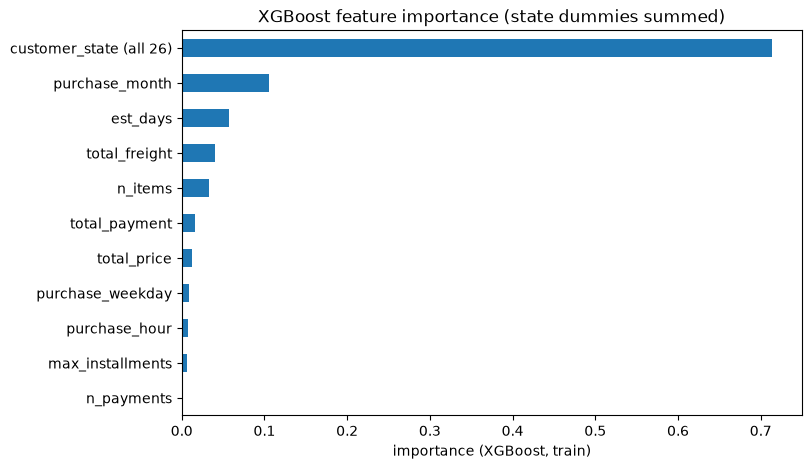

In [28]:
grouped_sorted = grouped.sort_values(ascending=True)
grouped_sorted.plot(kind="barh", figsize=(8, 5))
plt.xlabel("importance (XGBoost, train)")
plt.title("XGBoost feature importance (state dummies summed)")
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()